--- CUBIC SPLINE COEFFICIENTS ---
S1(x): a=  2.0000, b=  1.1022, c=  0.0000, d= -0.0601
S2(x): a=  0.0000, b= -3.4044, c= -0.9013, d=  1.3057
S3(x): a= -3.0000, b= -1.2899, c=  3.0158, d= -0.6854
S4(x): a=  1.0000, b=  2.5483, c= -1.0966, d= -0.4517


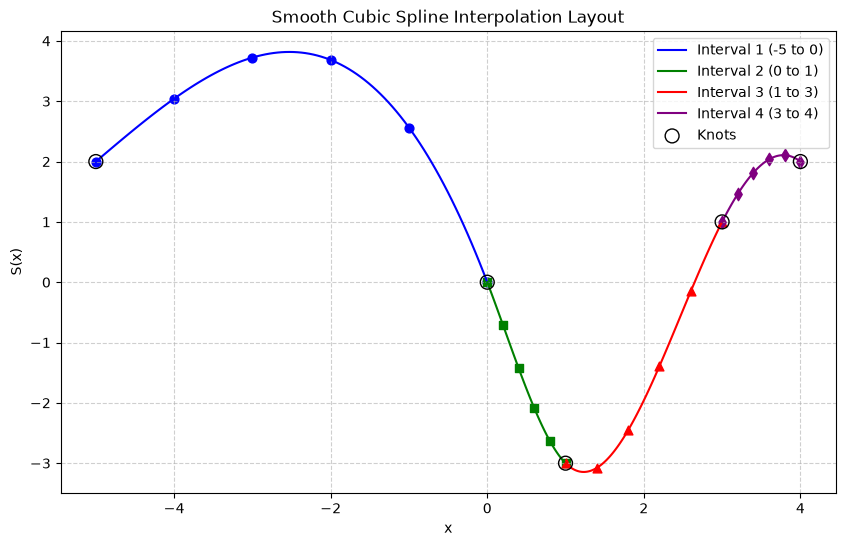

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the linear system (Hardcoded from Part A)
T = np.array([
    [10.0,  5.0,  0.0,  0.0,  0.0],
    [ 1.0, 12.0,  5.0,  0.0,  0.0],
    [ 0.0,  2.0,  6.0,  1.0,  0.0],
    [ 0.0,  0.0,  1.0,  6.0,  2.0],
    [ 0.0,  0.0,  0.0,  0.0,  1.0]
])
r = np.array([-6.0, -46.2, -12.0, 12.0, -1.0])

# Solve for unknown derivative values s_i
s = np.linalg.solve(T, r)

# Knots data
x_pts = np.array([-5.0, 0.0, 1.0, 3.0, 4.0])
y_pts = np.array([2.0, 0.0, -3.0, 1.0, 2.0])

# 2. Compute piecewise coefficients
intervals = [
    {"range": (-5, 0), "color": "blue", "marker": "o"},
    {"range": (0, 1),  "color": "green", "marker": "s"},
    {"range": (1, 3),  "color": "red", "marker": "^"},
    {"range": (3, 4),  "color": "purple", "marker": "d"}
]

print("--- CUBIC SPLINE COEFFICIENTS ---")
coeffs = []
for i in range(4):
    h = x_pts[i+1] - x_pts[i]
    dy = y_pts[i+1] - y_pts[i]
    
    a = y_pts[i]
    b = s[i]
    c = (3.0 * dy / h - 2.0 * b - s[i+1]) / h
    d = (b + s[i+1] - 2.0 * dy / h) / (h**2)
    coeffs.append((a, b, c, d))
    
    print(f"S{i+1}(x): a={a:8.4f}, b={b:8.4f}, c={c:8.4f}, d={d:8.4f}")

# 3. Visualize smoothly over finely spaced input samples
plt.figure(figsize=(10, 6))

for i in range(4):
    low, high = intervals[i]["range"]
    x_fine = np.linspace(low, high, 100)
    
    # Evaluate S_i(x) local coordinates relative to the left knot x_i
    x_local = x_fine - x_pts[i]
    a, b, c, d = coeffs[i]
    y_fine = a + b * x_local + c * x_local**2 + d * x_local**3
    
    # Plot interval curve with specific color
    plt.plot(x_fine, y_fine, color=intervals[i]["color"], 
             label=f"Interval {i+1} ({low} to {high})")
    
    # Add markers at sparse evaluation intervals to fit the prompt's layout request
    x_markers = np.linspace(low, high, 6)
    y_markers = a + b * (x_markers - x_pts[i]) + c * (x_markers - x_pts[i])**2 + d * (x_markers - x_pts[i])**3
    plt.scatter(x_markers, y_markers, color=intervals[i]["color"], marker=intervals[i]["marker"], s=40)

# Overlay initial target point markers
plt.scatter(x_pts, y_pts, color="black", zorder=5, s=100, facecolors='none', edgecolors='black', label="Knots")

plt.title("Smooth Cubic Spline Interpolation Layout", fontsize=12)
plt.xlabel("x")
plt.ylabel("S(x)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()
